# Bài 1 – Ảnh hưởng của số neuron

Phân loại hai nhóm điểm `make_moons`. Giữ nguyên hai tầng ẩn và ReLU, chỉ đổi số neuron mỗi tầng: **8, 32, 64, 128**.

**Cách dùng:** chọn kernel Python có các thư viện trong `requirements.txt`, rồi **Run All**.
Notebook đã lưu kết quả để có thể đọc ngay. Nếu chỉnh siêu tham số, chạy lại từ đầu;
các file trong `results/bai1` sẽ được cập nhật theo lần chạy mới.

MLP: đầu vào → các tầng ẩn → xác suất lớp. Mô hình học bằng dự đoán, tính loss,
lan truyền ngược và cập nhật trọng số bằng Adam.

## 1. Nạp thư viện

`common.py` cung cấp các hàm chia dữ liệu, đánh giá và xuất báo cáo dùng chung.
Hàm huấn luyện được trình bày ở phần 4 để tiện đọc thuật toán.
Nếu thiếu thư viện, chạy `python -m pip install -r Buoi1/requirements.txt` từ thư mục gốc.

In [1]:
from pathlib import Path
from types import SimpleNamespace
from copy import deepcopy
from time import perf_counter
import sys

# Chạy được khi kernel bắt đầu từ thư mục gốc hoặc từ Buoi1.
cwd = Path.cwd().resolve()
candidates = [cwd, cwd / "Buoi1", *[parent / "Buoi1" for parent in cwd.parents]]
BASE = next((path for path in candidates if (path / "common.py").is_file()), None)
if BASE is None:
    raise FileNotFoundError("Hãy mở notebook trong repository DeepL, cùng thư mục Buoi1/common.py.")
sys.path.insert(0, str(BASE))

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display, Markdown, Image
from sklearn.datasets import make_moons, load_digits
from sklearn.neural_network import MLPClassifier
from threadpoolctl import threadpool_limits
from common import Config, prepare_data, evaluate, count_parameters, save_results, format_value

%matplotlib inline

## 2. Chọn siêu tham số

- **Epoch:** số lượt học qua toàn bộ train.
- **Learning rate:** độ lớn bước cập nhật trọng số.
- **Batch size:** số mẫu dùng cho một bước cập nhật.
- **Seed:** kiểm soát khởi tạo và thứ tự dữ liệu; chạy nhiều seed để so sánh ổn định hơn.

Có thể thử nhanh với `EPOCHS = 20`, `SEEDS = [42]`. Giữ các giá trị này giống nhau giữa các cấu hình.

In [2]:
EPOCHS = 200
SEEDS = [42, 43, 44]
LEARNING_RATE = 0.001
BATCH_SIZE = 64

args = SimpleNamespace(
    epochs=EPOCHS, seeds=SEEDS, lr=LEARNING_RATE,
    batch_size=BATCH_SIZE, output_dir=BASE / "results" / "bai1",
)
assert EPOCHS >= 1 and LEARNING_RATE > 0 and BATCH_SIZE >= 1
assert SEEDS and len(set(SEEDS)) == len(SEEDS)
assert all(0 <= seed < 2**32 for seed in SEEDS)

## 3. Xem dữ liệu và cấu hình

Chia phân tầng **train/validation/test ≈ 60/20/20**, seed chia dữ liệu luôn bằng 42.
Train để cập nhật trọng số; validation để chọn checkpoint; test để đánh giá cuối.
`StandardScaler` chỉ học trung bình và độ lệch chuẩn từ train, tránh rò rỉ dữ liệu.

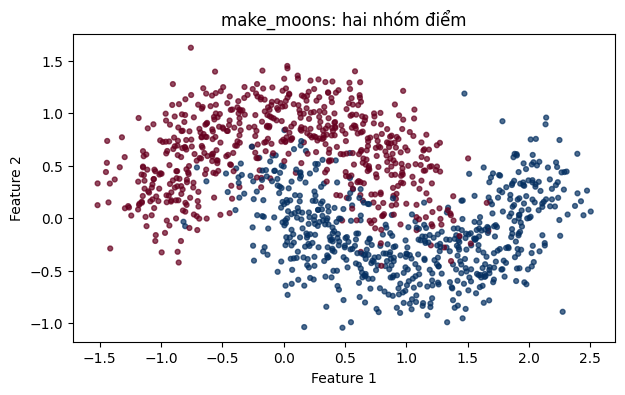

In [3]:
X, y = make_moons(n_samples=1200, noise=0.25, random_state=42)
data = prepare_data(X, y)

fig, ax = plt.subplots(figsize=(7, 4))
ax.scatter(X[:, 0], X[:, 1], c=y, cmap="RdBu", s=12, alpha=0.7)
ax.set(title="make_moons: hai nhóm điểm", xlabel="Feature 1", ylabel="Feature 2")
plt.show()

In [4]:
display(pd.DataFrame({
    "Tập": ["Train", "Validation", "Test"],
    "Số mẫu": [len(data.y_train), len(data.y_val), len(data.y_test)],
}))
print(f"Đầu vào: {X.shape[1]} đặc trưng; đầu ra: {len(np.unique(y))} lớp.")

,Tập,Số mẫu
0,Train,720
1,Validation,240
2,Test,240


Đầu vào: 2 đặc trưng; đầu ra: 2 lớp.


Hai tầng ẩn có cùng độ rộng; ví dụ `(32, 32)` nghĩa là hai tầng, mỗi tầng 32 neuron.
Giữ các yếu tố khác cố định để khảo sát riêng ảnh hưởng của độ rộng.

In [5]:
configs = [Config(f"width_{width}", (width, width)) for width in (8, 32, 64, 128)]

In [6]:
display(pd.DataFrame([
    {"Cấu hình": c.name, "Tầng ẩn": c.hidden,
     "Activation": "sigmoid" if c.activation == "logistic" else c.activation,
     "L2 alpha": c.alpha}
    for c in configs
]))

,Cấu hình,Tầng ẩn,Activation,L2 alpha
0,width_8,"(8, 8)",relu,0.0
1,width_32,"(32, 32)",relu,0.0
2,width_64,"(64, 64)",relu,0.0
3,width_128,"(128, 128)",relu,0.0


## 4. Huấn luyện và chọn checkpoint

Hàm dưới đây tạo MLP và gọi `partial_fit` một lần cho mỗi epoch.
Sau mỗi epoch, tính loss trên train và validation. Khi validation loss thấp hơn trước,
lưu bản sao mô hình. Chỉ đánh giá test sau khi đã chọn checkpoint.

Huấn luyện đủ số epoch để quan sát learning curve; mô hình dùng để đánh giá là bản
có **validation loss thấp nhất**, không nhất thiết là bản cuối cùng.
Hàm `evaluate` đo cross-entropy, accuracy và Macro-F1; `count_parameters` đếm trọng số và bias.

In [7]:
def train_classifier(config, data, *, epochs, seed, lr, batch_size):
    model = MLPClassifier(
        hidden_layer_sizes=config.hidden, activation=config.activation,
        solver="adam", alpha=config.alpha, batch_size=min(batch_size, len(data.y_train)),
        learning_rate_init=lr, random_state=seed, shuffle=True,
    )
    history = []
    best_loss = float("inf")
    best_epoch = 0
    best_model = None
    start = perf_counter()
    for epoch in range(1, epochs + 1):
        model.partial_fit(data.X_train, data.y_train, classes=np.unique(data.y_train))
        train_metrics = evaluate(model, data.X_train, data.y_train)
        val_metrics = evaluate(model, data.X_val, data.y_val)
        history.append({
            "config": config.name, "seed": seed, "epoch": epoch,
            **{f"train_{key}": value for key, value in train_metrics.items()},
            **{f"val_{key}": value for key, value in val_metrics.items()},
        })
        if val_metrics["loss"] < best_loss:
            best_loss = val_metrics["loss"]
            best_epoch = epoch
            best_model = deepcopy(model)
    elapsed = perf_counter() - start
    # Chỉ đánh giá test sau khi đã chọn checkpoint bằng validation loss.
    row = {
        "config": config.name, "seed": seed,
        "hidden_layers": "x".join(map(str, config.hidden)),
        "n_layers": len(config.hidden), "width": config.hidden[0],
        "activation": "sigmoid" if config.activation == "logistic" else config.activation,
        "alpha": config.alpha, "parameters": count_parameters(best_model),
        "seconds": elapsed, "best_epoch": best_epoch,
        **{f"train_{k}": v for k, v in evaluate(best_model, data.X_train, data.y_train).items()},
        **{f"val_{k}": v for k, v in evaluate(best_model, data.X_val, data.y_val).items()},
        **{f"test_{k}": v for k, v in evaluate(best_model, data.X_test, data.y_test).items()},
        "final_train_loss": history[-1]["train_loss"],
        "final_val_loss": history[-1]["val_loss"],
        "final_train_accuracy": history[-1]["train_accuracy"],
        "final_val_accuracy": history[-1]["val_accuracy"],
    }
    return row, history, best_model

In [8]:
rows, histories, models = [], [], {}
with threadpool_limits(limits=1):
    # Khởi động thư viện trước khi đo thời gian cấu hình đầu.
    MLPClassifier(hidden_layer_sizes=(2,), random_state=0).partial_fit(
        data.X_train[:64], data.y_train[:64], classes=np.unique(data.y_train),
    )
    for config in configs:
        for seed in args.seeds:
            row, history, model = train_classifier(
                config, data, epochs=args.epochs, seed=seed,
                lr=args.lr, batch_size=args.batch_size,
            )
            rows.append(row)
            histories.extend(history)
            if seed == args.seeds[0]:
                models[config.name] = model
            print(
                f"{config.name:12} | seed={seed} | epoch chọn={row['best_epoch']:3} | "
                f"val loss={row['val_loss']:.4f} | test accuracy={row['test_accuracy']:.2%}"
            )

runs = pd.DataFrame(rows)
history = pd.DataFrame(histories)
print(f"Hoàn tất {len(runs)} lượt huấn luyện.")

width_8      | seed=42 | epoch chọn=200 | val loss=0.1648 | test accuracy=93.75%


width_8      | seed=43 | epoch chọn=200 | val loss=0.1891 | test accuracy=93.75%


width_8      | seed=44 | epoch chọn=200 | val loss=0.2436 | test accuracy=92.92%


width_32     | seed=42 | epoch chọn=144 | val loss=0.1515 | test accuracy=95.00%


width_32     | seed=43 | epoch chọn=197 | val loss=0.1560 | test accuracy=95.00%


...

width_64     | seed=43 | epoch chọn= 78 | val loss=0.1508 | test accuracy=94.58%


width_64     | seed=44 | epoch chọn=149 | val loss=0.1483 | test accuracy=95.00%


width_128    | seed=42 | epoch chọn= 89 | val loss=0.1489 | test accuracy=94.58%


width_128    | seed=43 | epoch chọn= 76 | val loss=0.1509 | test accuracy=94.58%


width_128    | seed=44 | epoch chọn= 61 | val loss=0.1498 | test accuracy=95.00%
Hoàn tất 12 lượt huấn luyện.


## 5. Bảng so sánh

- **Loss:** cross-entropy của xác suất dự đoán, càng thấp càng tốt, không cộng L2.
- **Accuracy:** tỷ lệ đúng; **Macro-F1:** trung bình F1 của các lớp, càng cao càng tốt.
- **Số tham số:** trọng số + bias; phản ánh quy mô mạng.
- **Thời gian:** huấn luyện + đo train/validation + lưu checkpoint trong RAM;
  không gồm vẽ biểu đồ hoặc đánh giá test.

Bảng ghi **trung bình ± độ lệch chuẩn** giữa các seed. Accuracy/F1 dùng thang [0, 1].
Các seed dùng cùng lần chia dữ liệu; độ lệch chuẩn này không phải khoảng tin cậy.
Chọn cấu hình theo validation loss, không chọn theo kết quả test.

In [9]:
summary = save_results(
    configs, data, args, runs, history, models,
    title='Bài 1 – Ảnh hưởng của số neuron', dataset='make_moons (1.200 mẫu, noise=0.25)', boundaries=True,
)


Saved results: C:\Users\LeSonTruong\Documents\GitHub\DeepL\Buoi1\results\bai1


In [10]:
# Bảng ngắn để đọc; summary.csv vẫn chứa các cột số để xử lý tiếp.
table = summary[["config", "hidden_layers", "activation", "alpha", "parameters"]].copy()
for metric, label, precision in [
    ("val_loss", "Val loss", 4),
    ("test_loss", "Test loss", 4),
    ("test_accuracy", "Test accuracy", 4),
    ("test_macro_f1", "Test Macro-F1", 4),
    ("seconds", "Thời gian (s)", 2),
    ("best_epoch", "Epoch chọn", 1),
]:
    table[label] = summary.apply(lambda row: format_value(row, metric, precision), axis=1)
table = table.rename(columns={
    "config": "Cấu hình", "hidden_layers": "Tầng ẩn", "activation": "Activation",
    "alpha": "L2 alpha", "parameters": "Số tham số",
})
display(table.style.hide(axis="index"))

Cấu hình,Tầng ẩn,Activation,L2 alpha,Số tham số,Val loss,Test loss,Test accuracy,Test Macro-F1,Thời gian (s),Epoch chọn
width_8,8x8,relu,0.000000,105,0.1992 ± 0.0403,0.1664 ± 0.0225,0.9347 ± 0.0048,0.9347 ± 0.0048,1.19 ± 0.01,200.0 ± 0.0
width_32,32x32,relu,0.000000,1185,0.1516 ± 0.0043,0.1217 ± 0.0031,0.9500 ± 0.0000,0.9500 ± 0.0000,1.21 ± 0.01,178.3 ± 29.8
width_64,64x64,relu,0.000000,4417,0.1506 ± 0.0022,0.1224 ± 0.0011,0.9486 ± 0.0024,0.9486 ± 0.0024,1.34 ± 0.00,109.0 ± 36.3
width_128,128x128,relu,0.000000,17025,0.1499 ± 0.0010,0.1210 ± 0.0011,0.9472 ± 0.0024,0.9472 ± 0.0024,1.82 ± 0.02,75.3 ± 14.0


## 6. Biểu đồ

Learning curve hiển thị toàn bộ quá trình học, trung bình và độ lệch chuẩn giữa các seed.
**Underfitting:** train và validation đều chưa tốt; cũng có thể do học chưa đủ lâu.
**Overfitting:** train tiếp tục tốt lên nhưng validation xấu đi vì mô hình ghi nhớ train.

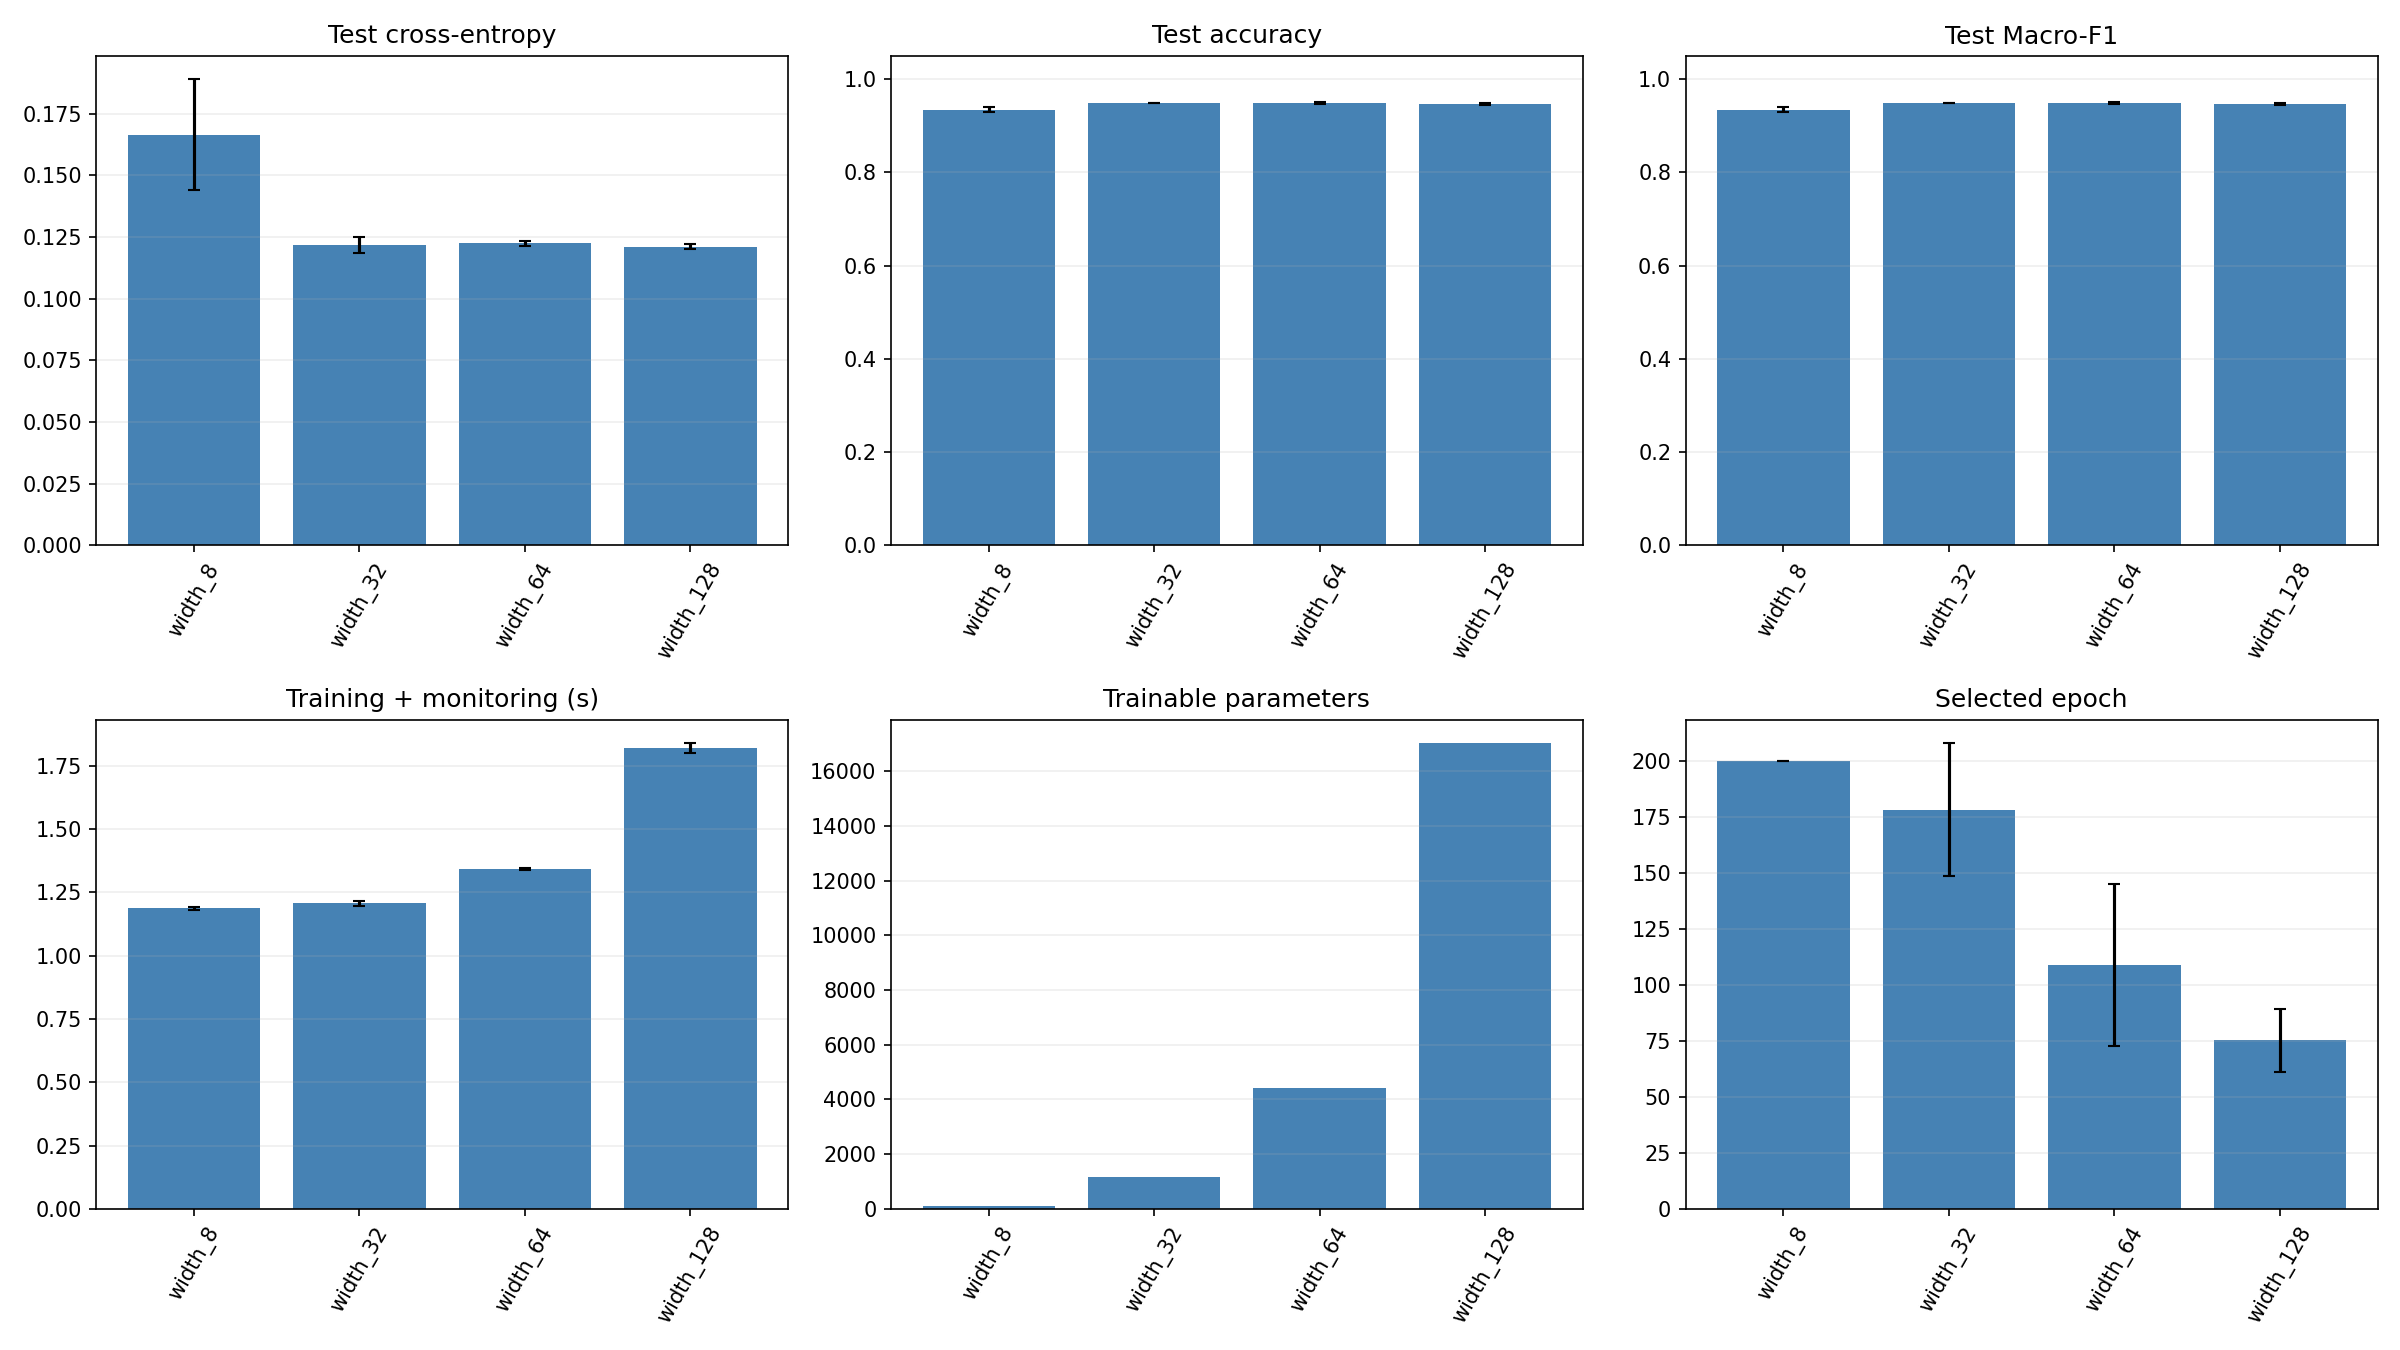

In [11]:
display(Image(filename=str(args.output_dir / "comparison.png")))

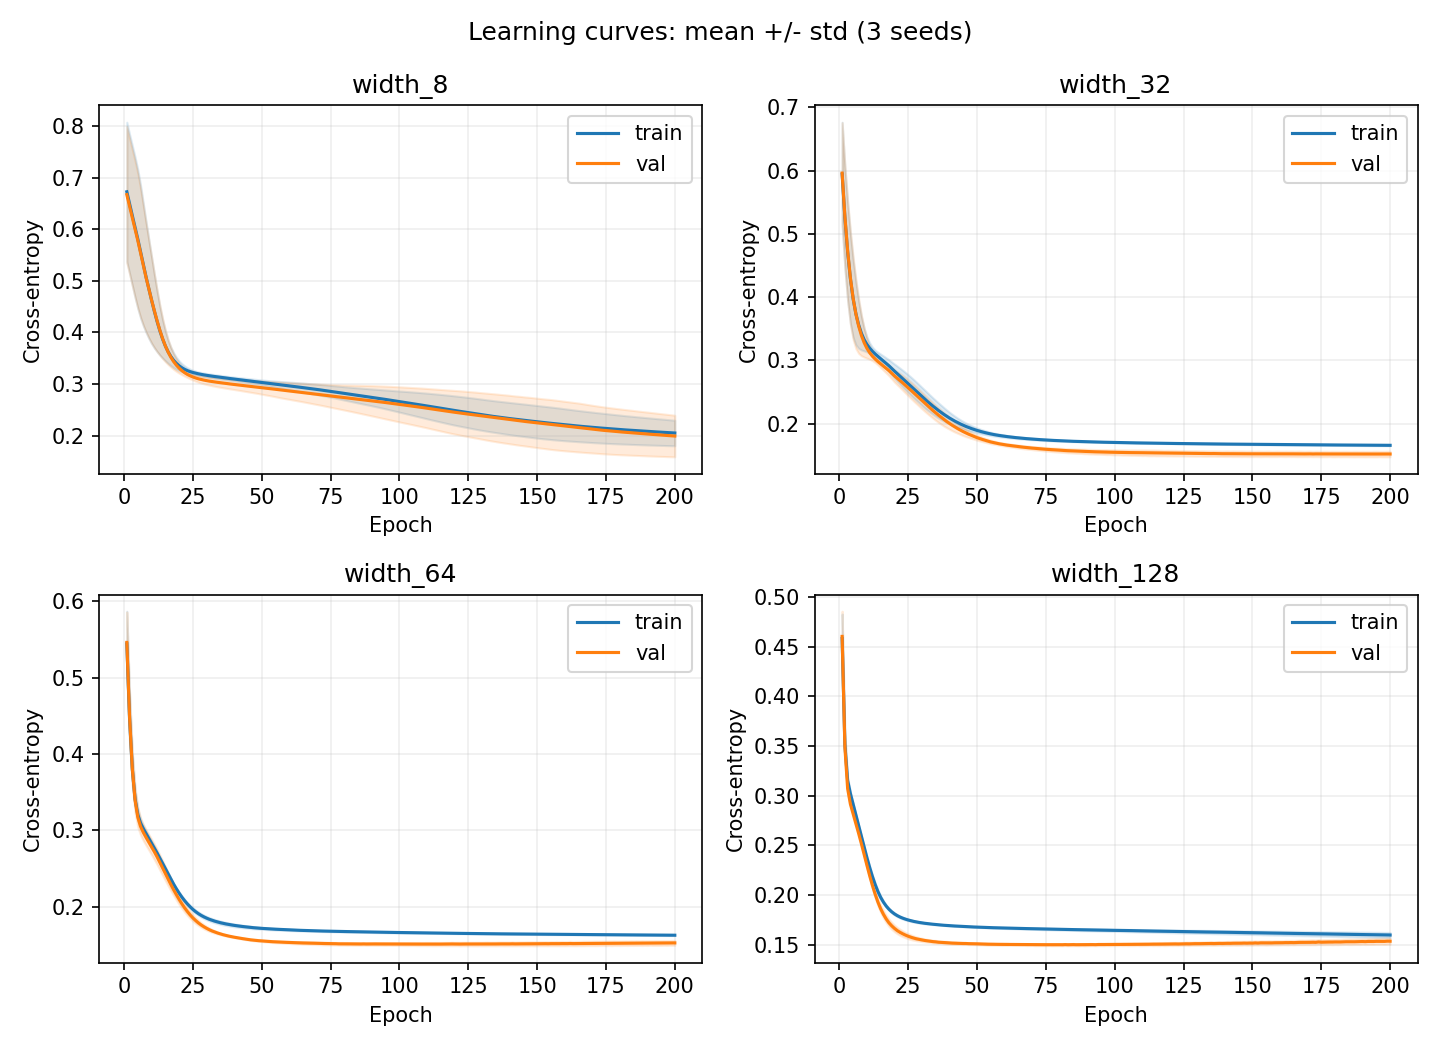

In [12]:
display(Image(filename=str(args.output_dir / "learning_loss.png")))

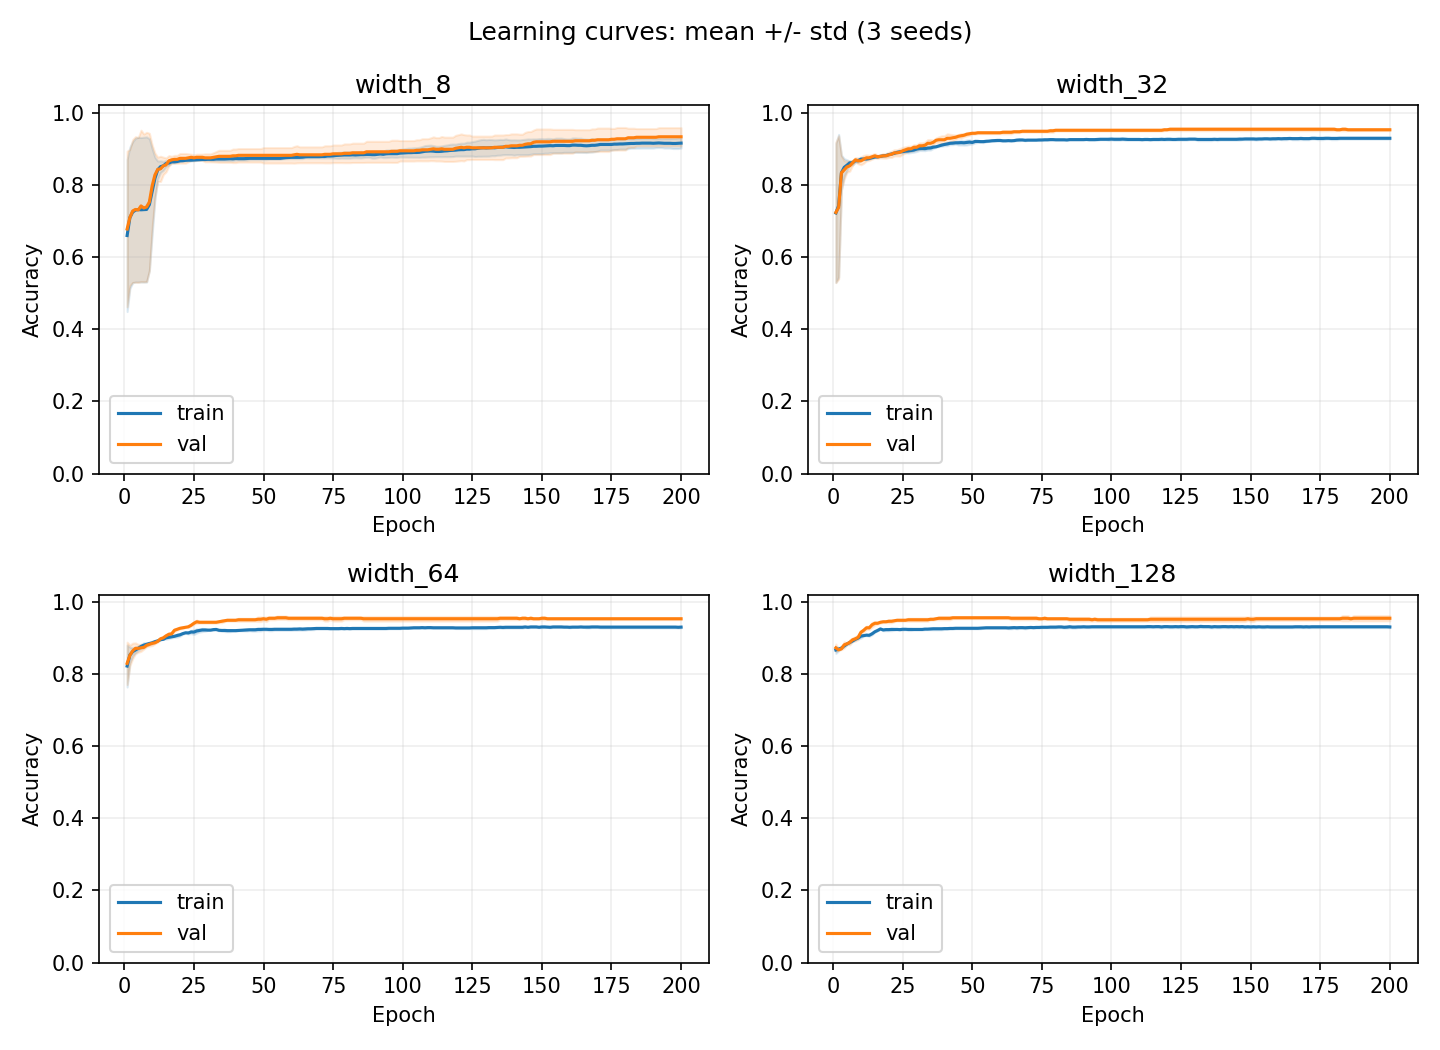

In [13]:
display(Image(filename=str(args.output_dir / "learning_accuracy.png")))

Biên quyết định của checkpoint từ seed đầu tiên. Các điểm trên hình thuộc tập test.
Vùng màu là xác suất dự đoán; đường đen là ranh giới xác suất 0.5.

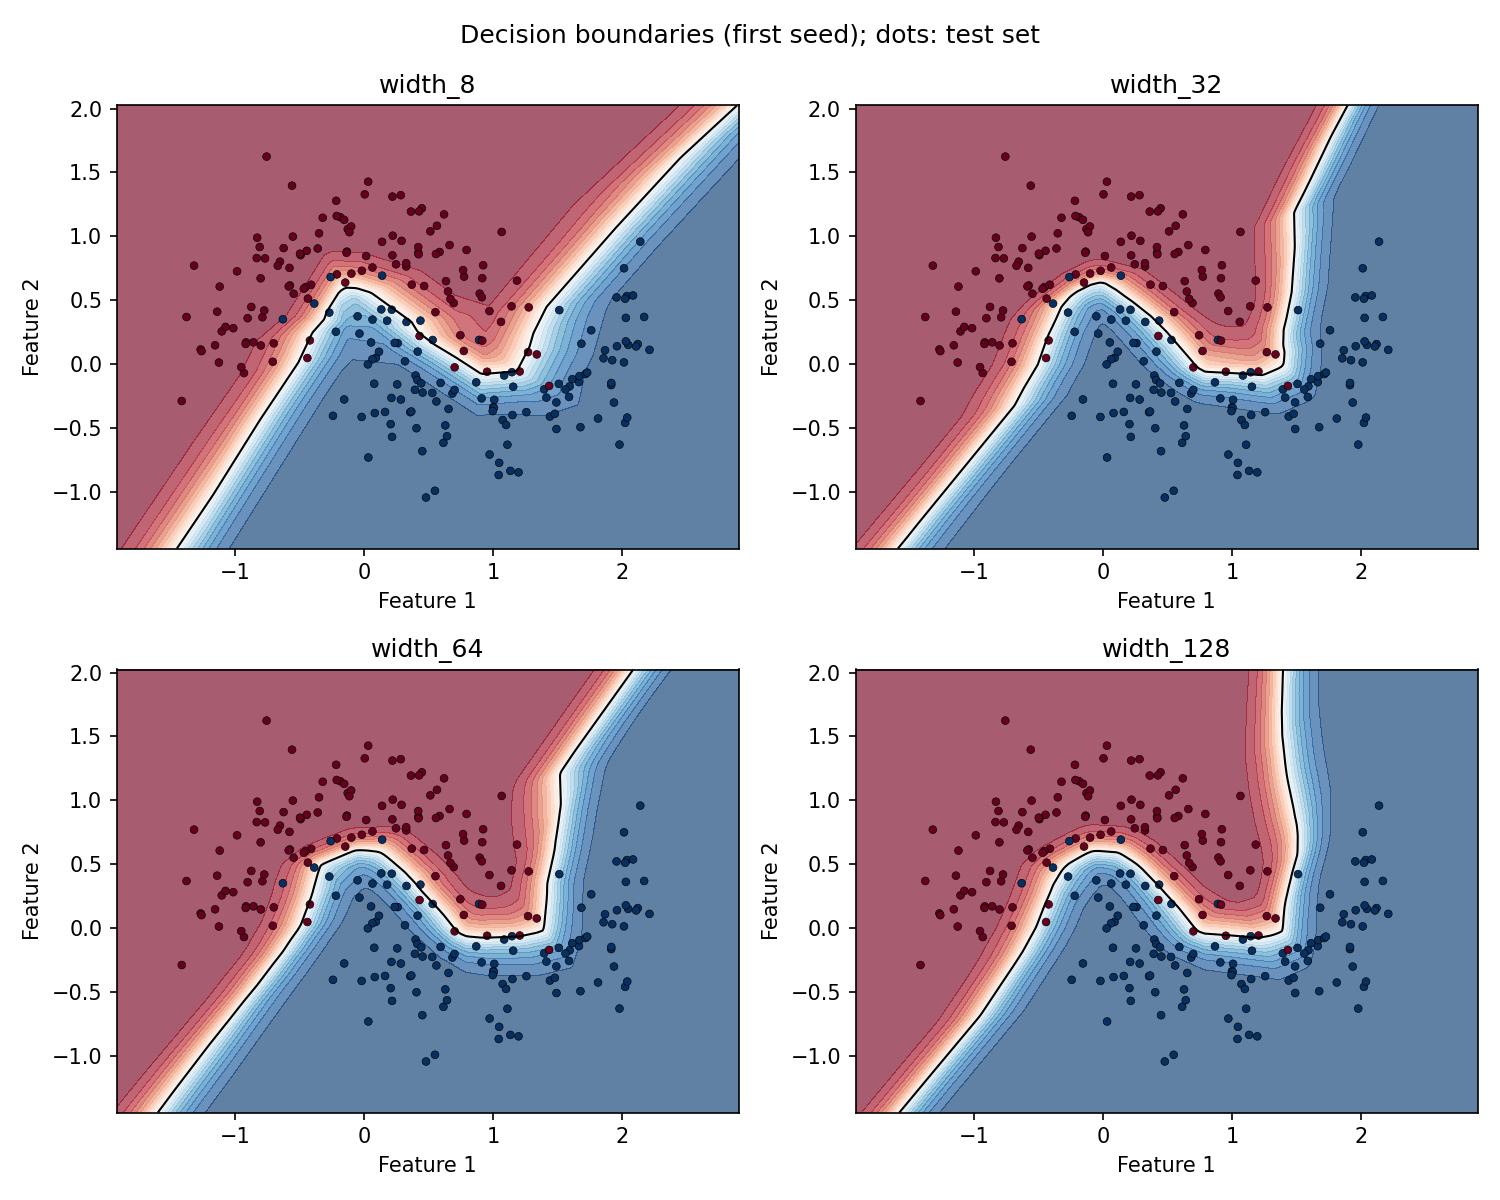

In [14]:
display(Image(filename=str(args.output_dir / "decision_boundaries.png")))

## 7. Nhận xét từ kết quả thực tế

Nhận xét dưới đây được tạo lại từ bảng của lần chạy hiện tại.
Các ngưỡng phát hiện underfitting/overfitting chỉ mang tính tham khảo; hãy đối chiếu learning curve.

In [15]:
report = (args.output_dir / "report.md").read_text(encoding="utf-8")
notes = report.split("## Nhận xét ngắn\n\n", 1)[1].split("\n## Biểu đồ", 1)[0]
display(Markdown(notes))

- Theo validation loss trung bình, **width_128** tốt nhất (0.1499); checkpoint của cấu hình này có test accuracy 94.72%, Macro-F1 0.9472. Dùng validation để chọn cấu hình; test chỉ dùng báo cáo đánh giá cuối.
- Từ 8 lên 128 neuron mỗi tầng, số tham số tăng từ 105 lên 17025 (162.1 lần); test accuracy thay đổi từ 93.47% thành 94.72%, thời gian từ 1.19s thành 1.82s. Nhiều neuron tăng khả năng biểu diễn và chi phí; chất lượng còn phụ thuộc nhiễu và tối ưu, không bảo đảm tăng đều theo độ rộng.
- Chưa thấy dấu hiệu overfitting rõ theo tiêu chí: train loss cuối giảm thêm >0.005 trong khi val loss tăng >0.02 so với checkpoint tốt nhất. Khoảng cách train/validation nhỏ không đủ để khẳng định không overfit.
- Không cấu hình nào có cả accuracy train/validation cuối dưới 90%. Không có bằng chứng underfitting rõ theo ngưỡng tham khảo này; hãy đối chiếu learning curve thay vì chỉ nhìn test accuracy.
- Các seed chỉ phản ánh biến động khởi tạo và thứ tự batch; chưa đo độ bất định giữa nhiều lần chia dữ liệu. Các ngưỡng chẩn đoán trên là quy ước tham khảo, không phải kiểm định thống kê.


## 8. File kết quả

Kết quả đã lưu tại `results/bai1/`: `summary.csv`, `runs.csv`, `history.csv`,
`metadata.json`, `report.md` và các biểu đồ PNG. Notebook cũng lưu output để đọc mà không cần chạy lại.

Khi trình bày: nêu **đã thay yếu tố nào → số đo thay đổi ra sao → nhận xét vì sao**.
Không kết luận mạng lớn luôn tốt hơn hoặc có ít test accuracy nghĩa là underfitting;
cần xem cả train, validation và learning curve.